# Week 5 - Transfer Learning

## **Name:** M. Abuzar Shoukat
## **Project:** Project 2, Scene Classification with Transfer Learning 
## **Subject:** Introduction to Applied AI

In [3]:
import os
import time
import copy
import glob
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms, models
from sklearn.metrics import (classification_report, confusion_matrix,
                             ConfusionMatrixDisplay)

torch.manual_seed(42)
np.random.seed(42)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device)   # must say cuda; if not, turn on the GPU

# Auto-find the dataset path (works with any Kaggle folder layout)
TRAIN_DIR = glob.glob('/kaggle/input/**/seg_train/seg_train', recursive=True)[0]
TEST_DIR = glob.glob('/kaggle/input/**/seg_test/seg_test', recursive=True)[0]
print('Train dir:', TRAIN_DIR)
print('Test dir:', TEST_DIR)

classes = sorted(os.listdir(TRAIN_DIR))
for c in classes:
    n_tr = len(os.listdir(os.path.join(TRAIN_DIR, c)))
    n_te = len(os.listdir(os.path.join(TEST_DIR, c)))
    print(f'{c:10s} train {n_tr:5d}   test {n_te:4d}')

Device: cuda
Train dir: /kaggle/input/datasets/puneet6060/intel-image-classification/seg_train/seg_train
Test dir: /kaggle/input/datasets/puneet6060/intel-image-classification/seg_test/seg_test
buildings  train  2191   test  437
forest     train  2271   test  474
glacier    train  2404   test  553
mountain   train  2512   test  525
sea        train  2274   test  510
street     train  2382   test  501


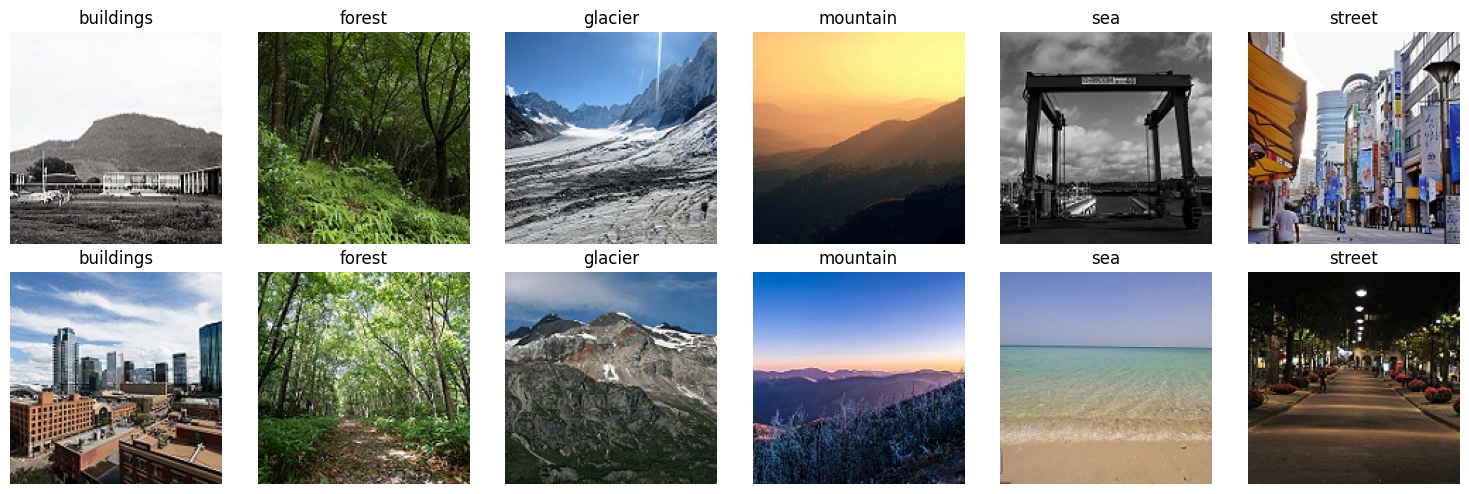

Shape (H, W, C): (150, 150, 3)  dtype: uint8  range: 0 to 255
Top-left 3x3 of the red channel:
 [[8 6 3]
 [6 5 4]
 [5 5 5]]


In [4]:
fig, axes = plt.subplots(2, 6, figsize=(15, 5))
for j, c in enumerate(classes):
    files = sorted(os.listdir(os.path.join(TRAIN_DIR, c)))[:2]
    for i, f in enumerate(files):
        img = Image.open(os.path.join(TRAIN_DIR, c, f))
        axes[i, j].imshow(img)
        axes[i, j].set_title(c)
        axes[i, j].axis('off')
plt.tight_layout()
plt.show()

arr = np.array(img)
print('Shape (H, W, C):', arr.shape, ' dtype:', arr.dtype,
      ' range:', arr.min(), 'to', arr.max())
print('Top-left 3x3 of the red channel:\n', arr[:3, :3, 0])

## Part 1: Write it

**Dataset:** The Intel Image Classification dataset has 6 classes: buildings, forest, glacier, mountain, sea, street.

| Class | Train | Test |
|---|---|---|
| buildings | 2191 | 437 |
| forest | 2271 | 474 |
| glacier | 2404 | 553 |
| mountain | 2512 | 525 |
| sea | 2274 | 510 |
| street | 2382 | 501 |
| **Total** | **14,034** | **3,000** |

**Which classes look similar:** Glacier and mountain both show snowy peaks, rock and sky in similar colors, as in the sample grid above. Buildings and street share many of the same objects (roads, houses, cars). Sea and glacier both have large blue/white areas.

**My prediction:** The model will confuse **glacier and mountain** the most, because both contain snow, rock and sky with similar colors and textures.

**Image as numbers:**
- Shape (H, W, C): (150, 150, 3)
- Data type: uint8
- Value range: 0 to 255

An image is a 3D array of height x width x 3 color channels (red, green, blue). Each number is the brightness of one color at one pixel, from 0 (dark) to 255 (bright). The top-left 3x3 red values are small (3 to 8), so that corner of the first image is very dark.

tensor([[30., 30.,  0.],
        [30., 30.,  0.],
        [30., 30.,  0.]])


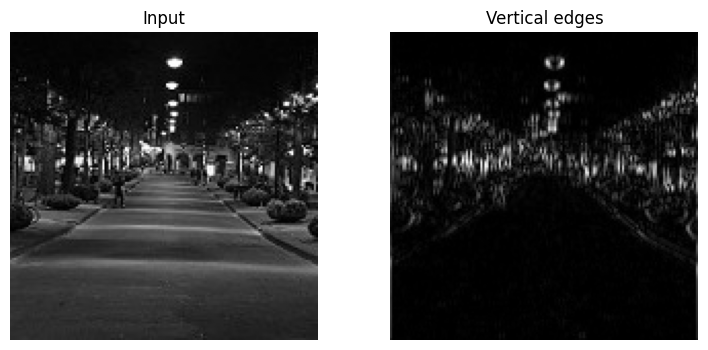

In [5]:
# The 5x5 example from the lecture: a vertical edge
x = torch.tensor([[0, 0, 10, 10, 10]] * 5, dtype=torch.float32)
k = torch.tensor([[-1, 0, 1]] * 3, dtype=torch.float32)
out = F.conv2d(x.view(1, 1, 5, 5), k.view(1, 1, 3, 3))
print(out.squeeze())            # expect three rows of [30, 30, 0]

# The same kernel on a real photo, converted to grayscale
g = transforms.functional.to_tensor(img.convert('L')).unsqueeze(0)
edges = F.conv2d(g, k.view(1, 1, 3, 3), padding=1)
fig, ax = plt.subplots(1, 2, figsize=(9, 4))
ax[0].imshow(g.squeeze(), cmap='gray')
ax[0].set_title('Input')
ax[1].imshow(edges.squeeze().abs(), cmap='gray')
ax[1].set_title('Vertical edges')
for a in ax:
    a.axis('off')
plt.show()

In [6]:
def count(m):
    return sum(p.numel() for p in m.parameters())

conv = nn.Conv2d(in_channels=3, out_channels=64, kernel_size=3, padding=1)
dense = nn.Linear(150 * 150 * 3, 512)
print(f'Conv 3x3, 3 -> 64  : {count(conv):,} parameters')   # (3*3*3+1)*64
print(f'Dense 67,500 -> 512 : {count(dense):,} parameters')

t = torch.randn(1, 3, 224, 224)
for stride in [1, 2]:
    c = nn.Conv2d(3, 64, kernel_size=3, stride=stride, padding=1)
    print(f'stride {stride}: output {tuple(c(t).shape)}')    # (W-K+2P)/S + 1
print('2x2 max pool:', tuple(F.max_pool2d(t, 2).shape))

Conv 3x3, 3 -> 64  : 1,792 parameters
Dense 67,500 -> 512 : 34,560,512 parameters
stride 1: output (1, 64, 224, 224)
stride 2: output (1, 64, 112, 112)
2x2 max pool: (1, 3, 112, 112)


## Part 2: Write it

**Convolution by hand:** The kernel [-1, 0, 1] slides over each row of the
5x5 image, whose rows are [0, 0, 10, 10, 10].
- Window on columns 1-3: (-1)(0) + (0)(0) + (1)(10) = 10 per row, x 3 rows = 30
- Window on columns 2-4: (-1)(0) + (0)(10) + (1)(10) = 10 per row, x 3 rows = 30
- Window on columns 3-5: (-1)(10) + (0)(10) + (1)(10) = 0 per row, x 3 rows = 0

So each output row is [30, 30, 0], matching the PyTorch output. The kernel
responds strongly where brightness increases from left to right (the edge)
and gives 0 on the flat region.

**Parameter counts:**
- Conv 3x3, 3 -> 64: (K x K x C_in + 1) x C_out = (3 x 3 x 3 + 1) x 64
  = 28 x 64 = **1,792**
- Dense 67,500 -> 512: 67,500 x 512 weights + 512 biases
  = 34,560,000 + 512 = **34,560,512**
- The dense layer needs 34,560,512 / 1,792 = about **19,286 times more**
  parameters.

**Output sizes:** (W - K + 2P) / S + 1
- Stride 1: (224 - 3 + 2) / 1 + 1 = 224
- Stride 2: floor((224 - 3 + 2) / 2) + 1 = 111 + 1 = 112
- 2x2 max pool halves height and width: 224 -> 112

**Why weight sharing helps:** A convolution reuses the same small kernel at
every position, so an edge or texture is detected the same way wherever it
appears in the image. The model therefore does not have to relearn the same
object for each location, which needs far fewer parameters and generalizes
better.

In [7]:
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]   # ImageNet stats

train_tf = transforms.Compose([
    transforms.RandomResizedCrop(224, scale=(0.7, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD)])
eval_tf = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD)])

# Two views of the same folder: augmented for training, clean for validation
full_aug = datasets.ImageFolder(TRAIN_DIR, transform=train_tf)
full_eval = datasets.ImageFolder(TRAIN_DIR, transform=eval_tf)
idx = np.random.permutation(len(full_aug))
n_val = int(0.15 * len(idx))
train_ds = Subset(full_aug, idx[n_val:])
val_ds = Subset(full_eval, idx[:n_val])
test_ds = datasets.ImageFolder(TEST_DIR, transform=eval_tf)

train_dl = DataLoader(train_ds, batch_size=64, shuffle=True, num_workers=2)
val_dl = DataLoader(val_ds, batch_size=128, num_workers=2)
test_dl = DataLoader(test_ds, batch_size=128, num_workers=2)
print(len(train_ds), 'train |', len(val_ds), 'val |', len(test_ds), 'test')

11929 train | 2105 val | 3000 test


## Part 3: Write it

**Images in each split:**
- Train: 11,929
- Validation: 2,105
- Test: 3,000
- Total training folder: 14,034 (split 85% train / 15% validation, test is a separate folder)

**Augmentation that would be wrong for this dataset:** Vertical flip
(or a 180-degree rotation). In scene photos, the sky is always above and the
ground or sea below. A flipped image would show an upside-down world that
never appears in real test images, so the model would waste capacity learning
unrealistic inputs.

**Augmentation that would be wrong for handwritten digits:** Horizontal flip.
A flipped 2 or 5 looks like a different, non-existent symbol, and rotating a
6 by 180 degrees turns it into a 9, which changes the label.

**Why augmentation is on training data only:** Augmentation exists to make the
model see more varied training examples. Validation and test images must stay
clean (only resized and normalized) so the accuracy we measure reflects real,
unmodified images and is comparable between epochs.

In [ ]:
def run_epoch(model, loader, optimizer=None):
    """One pass over the data. Trains only if an optimizer is given."""
    training = optimizer is not None
    model.train(training)
    total_loss, correct, n = 0.0, 0, 0
    with torch.set_grad_enabled(training):
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            logits = model(xb)                       # forward pass
            loss = F.cross_entropy(logits, yb)       # softmax + log loss
            if training:
                optimizer.zero_grad()
                loss.backward()                      # backpropagation
                optimizer.step()                     # gradient step
            total_loss += loss.item() * len(yb)
            correct += (logits.argmax(1) == yb).sum().item()
            n += len(yb)
    return total_loss / n, correct / n


def fit(model, optimizer, epochs, history):
    best_acc, best_state = -1.0, None
    for ep in range(epochs):
        t0 = time.time()
        tr_loss, tr_acc = run_epoch(model, train_dl, optimizer)
        va_loss, va_acc = run_epoch(model, val_dl)
        history.append((tr_loss, va_loss, tr_acc, va_acc))
        if va_acc > best_acc:
            best_acc = va_acc
            best_state = copy.deepcopy(model.state_dict())
        print(f'epoch {ep + 1}: train loss {tr_loss:.3f} acc {tr_acc:.3f} | '
              f'val loss {va_loss:.3f} acc {va_acc:.3f} '
              f'({time.time() - t0:.0f}s)')
    model.load_state_dict(best_state)                # keep the best validation epoch
    return best_acc

In [16]:
model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
for p in model.parameters():
    p.requires_grad = False                          # freeze the body
model.fc = nn.Linear(model.fc.in_features, len(classes))   # new 6-class head
model = model.to(device)

trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'Trainable {trainable:,} of {count(model):,} parameters')

history = []
opt = torch.optim.Adam(model.fc.parameters(), lr=1e-3)
best = fit(model, opt, epochs=3, history=history)
print(f'Best validation accuracy, feature extraction: {best:.3f}')

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 239MB/s]


Trainable 3,078 of 11,179,590 parameters
epoch 1: train loss 0.588 acc 0.809 | val loss 0.327 acc 0.894 (49s)
epoch 2: train loss 0.326 acc 0.890 | val loss 0.290 acc 0.899 (35s)
epoch 3: train loss 0.299 acc 0.895 | val loss 0.276 acc 0.901 (34s)
Best validation accuracy, feature extraction: 0.901


## Part 4: Write it

**Validation accuracy per epoch (feature extraction):**
- Epoch 1: 0.894
- Epoch 2: 0.899
- Epoch 3: 0.901
- Best: 0.901

**Trainable parameters:** 3,078 of 11,179,590 (512 x 6 weights + 6 biases), about 0.03% of the network.

**Why high accuracy is possible with so few trained parameters:** The ResNet-18 body was pretrained on ImageNet, so its frozen layers already extract a feature hierarchy: edges and colors first, then textures and parts, then object-like shapes. Scene classes are made of these same features, so the new linear layer only has to learn how to combine them. Accuracy was already 0.894 after one epoch.

In [28]:
for p in model.layer4.parameters():
    p.requires_grad = True                      # unfreeze the last block

opt = torch.optim.Adam([
    {'params': model.layer4.parameters(), 'lr': 1e-4},   # gentle: pretrained
    {'params': model.fc.parameters(), 'lr': 1e-3}])      # faster: new head
trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'Trainable now: {trainable:,}')
best = fit(model, opt, epochs=3, history=history)
print(f'Best validation accuracy, fine-tuned: {best:.3f}')

Trainable now: 8,396,806
epoch 1: train loss 0.135 acc 0.952 | val loss 0.227 acc 0.926 (35s)
epoch 2: train loss 0.102 acc 0.964 | val loss 0.237 acc 0.930 (35s)
epoch 3: train loss 0.083 acc 0.969 | val loss 0.245 acc 0.932 (35s)
Best validation accuracy, fine-tuned: 0.932


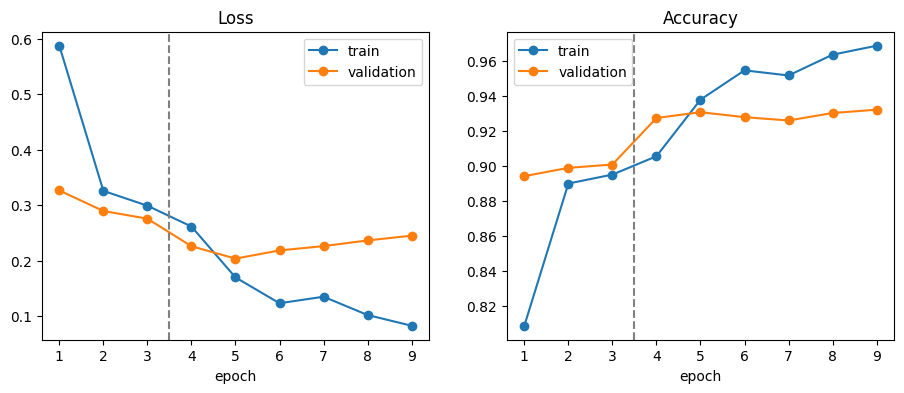

In [29]:
h = np.array(history)
ep = np.arange(1, len(h) + 1)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(ep, h[:, 0], 'o-', label='train')
ax[0].plot(ep, h[:, 1], 'o-', label='validation')
ax[1].plot(ep, h[:, 2], 'o-', label='train')
ax[1].plot(ep, h[:, 3], 'o-', label='validation')
for a, title in zip(ax, ['Loss', 'Accuracy']):
    a.axvline(3.5, color='gray', ls='--')       # where fine-tuning starts
    a.set_title(title)
    a.set_xlabel('epoch')
    a.legend()
plt.show()

## Part 5: Write it

| Epoch | Phase | Val accuracy |
|---|---|---|
| 1 | Feature extraction | 0.894 |
| 2 | Feature extraction | 0.899 |
| 3 | Feature extraction | 0.901 |
| 4 | Fine-tuning | 0.926 |
| 5 | Fine-tuning | 0.930 |
| 6 | Fine-tuning | 0.932 |

**Did fine-tuning help?** Yes. Best validation accuracy rose from 0.901 to 0.932, an improvement of 3.1 percentage points. Unfreezing layer4 (about 8.4M parameters) with a learning rate of 1e-4 let the last block adapt to scene images, and the new head kept 1e-3.

**What the curves show:** Accuracy jumps at epoch 4, when fine-tuning starts, and then creeps up slowly. Training loss keeps falling (0.135, 0.102, 0.083), but validation loss goes the other way (0.227, 0.237, 0.245).

**Overfitting?** There is a mild sign of it in epochs 4 to 6. Training loss falls while validation loss rises from 0.227 to 0.245, and the gap between training accuracy (0.969) and validation accuracy (0.932) widens. Validation accuracy still edged up, so the best epoch is the last one, but more epochs would likely hurt.

**Why training accuracy can be lower than validation accuracy:** In epoch 1, training accuracy was 0.809 and validation was 0.894. Training images are randomly cropped, flipped and color-jittered, so they are harder than the clean validation images. Training accuracy is also averaged while the weights are still changing during the epoch.

Test accuracy: 0.924
              precision    recall  f1-score   support

   buildings      0.938     0.892     0.914       437
      forest      0.994     0.987     0.990       474
     glacier      0.927     0.830     0.876       553
    mountain      0.873     0.901     0.887       525
         sea      0.912     0.990     0.949       510
      street      0.914     0.952     0.933       501

    accuracy                          0.924      3000
   macro avg      0.926     0.926     0.925      3000
weighted avg      0.925     0.924     0.923      3000



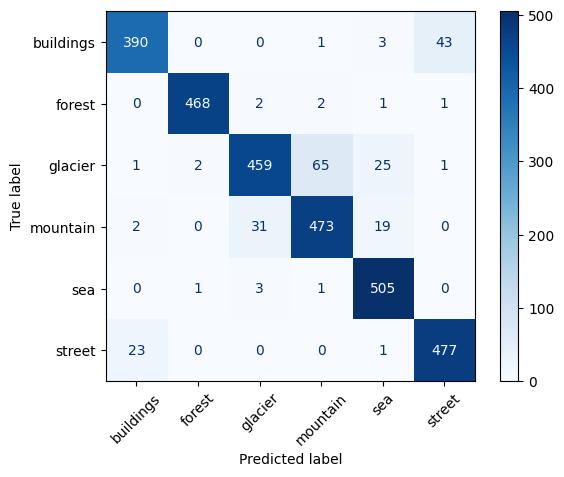

In [30]:
model.eval()
probs, preds, labels = [], [], []
with torch.no_grad():
    for xb, yb in test_dl:
        p = F.softmax(model(xb.to(device)), dim=1).cpu()
        probs.append(p)
        preds.append(p.argmax(1))
        labels.append(yb)
probs, preds, labels = torch.cat(probs), torch.cat(preds), torch.cat(labels)

print(f'Test accuracy: {(preds == labels).float().mean():.3f}')
print(classification_report(labels, preds, target_names=classes, digits=3))
cm = confusion_matrix(labels, preds)
ConfusionMatrixDisplay(cm, display_labels=classes).plot(
    cmap='Blues', xticks_rotation=45)
plt.show()

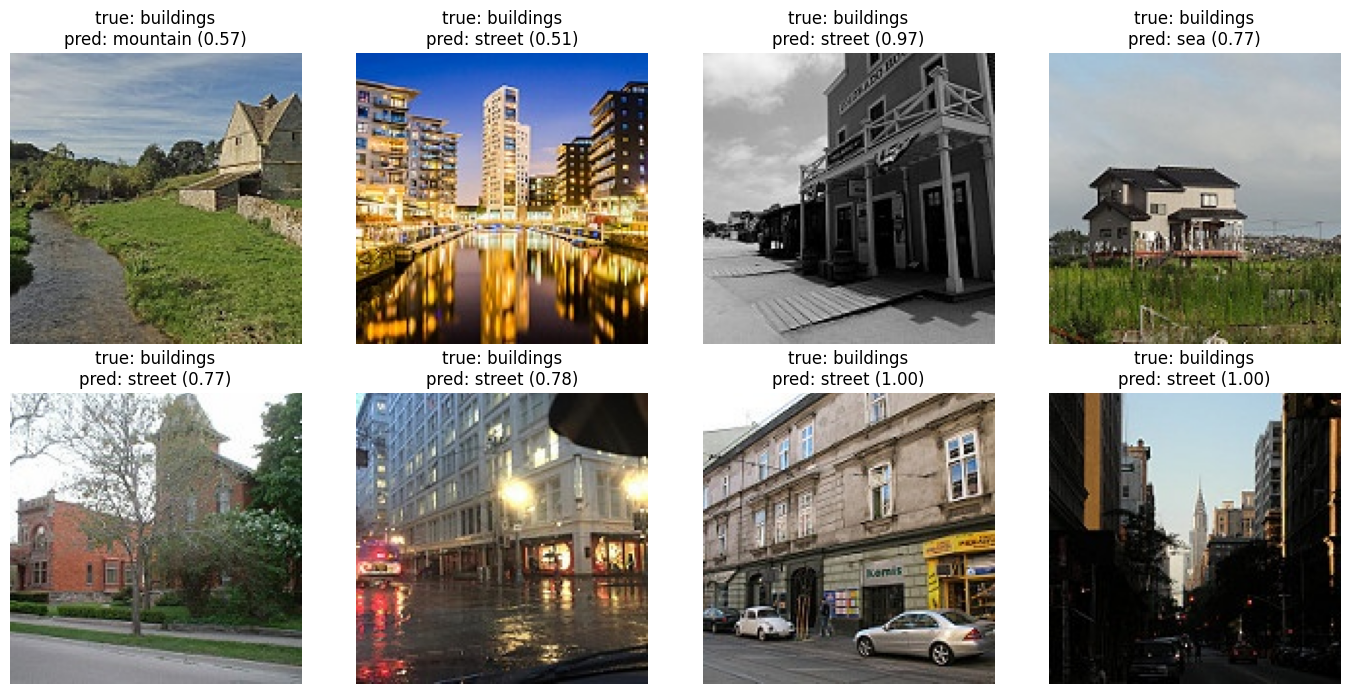

In [31]:
wrong = torch.where(preds != labels)[0][:8]
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for ax in axes.flat:
    ax.axis('off')
for ax, i in zip(axes.flat, wrong.tolist()):
    path, _ = test_ds.samples[i]
    ax.imshow(Image.open(path))
    ax.set_title(f'true: {classes[labels[i]]}\n'
                 f'pred: {classes[preds[i]]} ({probs[i].max():.2f})')
plt.tight_layout()
plt.show()

In [32]:
x0, y0 = test_ds[0]
with torch.no_grad():
    logits = model(x0.unsqueeze(0).to(device)).cpu().squeeze()
p = F.softmax(logits, dim=0)
print('True class:', classes[y0])
for c, z, q in zip(classes, logits.tolist(), p.tolist()):
    print(f'{c:10s} logit {z:6.2f}   probability {q:.3f}')

True class: buildings
buildings  logit   9.80   probability 1.000
forest     logit  -9.45   probability 0.000
glacier    logit  -8.37   probability 0.000
mountain   logit  -4.81   probability 0.000
sea        logit  -5.48   probability 0.000
street     logit  -3.72   probability 0.000


## Part 6: Write it

**Test accuracy (evaluated once):** 0.924 on 3,000 images.

**Two weakest classes by recall:**
1. glacier: recall 0.830
2. buildings: recall 0.892

**Most confused pair:** glacier predicted as mountain, 65 images. Mountain predicted as glacier was 31 more, so glacier and mountain together account for 96 errors. The second pair is buildings and street: 43 buildings were predicted as street and 23 streets as buildings.

**Was my Part 1 prediction right?** Yes. I predicted glacier and mountain, and they were the most confused pair. Both contain snow, rock and sky in similar colors. I did not expect buildings and street to be second, but they share roads, cars and houses.

**Error gallery analysis:** All 8 images shown are true "buildings" images.
1. Image 4 (true: buildings, predicted: sea, confidence 0.77): the model was wrong. It is a house in a grass field under a flat grey sky, and the model probably used the large sky and horizon as a sea cue.
2. Image 7 (true: buildings, predicted: street, confidence 1.00): the image is genuinely ambiguous. It shows a building facade with a road and parked cars, so "street" is a reasonable label too. The model was very confident, which shows confidence is not the same as being correct.

**Softmax output for one image:** The true class was buildings. Its logit was 9.80 and its probability 1.000. The other five logits were all negative (-3.72 to -9.45), so their probabilities round to 0.000. The probabilities sum to 1, and the largest logit gets the largest probability.

In [33]:
path = '/kaggle/working/resnet18_intel.pt'
torch.save(model.state_dict(), path)
print(f'Saved {path} ({os.path.getsize(path) / 1e6:.1f} MB)')

Saved /kaggle/working/resnet18_intel.pt (44.8 MB)


## Check Your Understanding

**1. Why does a network without nonlinear activations collapse to a single linear layer?**
Each layer computes W*x + b, and stacking two gives W2(W1 x + b1) + b2 = (W2 W1) x + (W2 b1 + b2). That is one matrix times x plus one bias, so any number of linear layers is equivalent to a single linear layer. A nonlinearity such as ReLU between layers is what lets depth add expressive power.

**2. For logits [3, 1, 0], what probability does softmax give the first class?**
e^3 = 20.086, e^1 = 2.718, e^0 = 1.000. Sum = 23.804.
P(first class) = 20.086 / 23.804 = **0.844**

**3. How many parameters does a 3 x 3 convolution from 64 to 128 channels have?**
(K x K x C_in + 1) x C_out = (3 x 3 x 64 + 1) x 128 = 577 x 128 = **73,856**

**4. Output size for a 56 x 56 input, 3 x 3 kernel, padding 1, stride 2?**
(W - K + 2P) / S + 1 = (56 - 3 + 2) / 2 + 1 = 27.5 -> floor 27, then 27 + 1 = **28**, so the output is 28 x 28.

**5. Why does a residual (skip) connection help gradients reach the early layers?**
A residual block computes y = F(x) + x, so dy/dx = dF/dx + 1. The "+1" gives the gradient a direct path backward that does not pass through the weights, so it cannot shrink toward zero as it travels through many layers (the vanishing gradient problem). Early layers still receive a useful learning signal.

**6. When would you train a CNN from scratch instead of using transfer learning?**
When the images are very different from ImageNet (for example medical scans, spectrograms or multispectral satellite data with a different number of channels), when there is a very large labeled dataset, or when the model must be much smaller than ResNet-18 for a constrained device.